# Популяционная структура нута по локусам транспозонов

Проверяем, могут ли дрейф и простая миграция воспроизвести распределение частот аллелей в шести региональных выборках нута. Затем оцениваем, насколько группировки регионов зависят от метрики генетического расстояния.

Отчёт открывается с готовыми результатами. Для повторного расчёта нужны три исходных файла в каталоге `data/`, перечисленных в README. Установите `RECOMPUTE = True` и выполните все ячейки. Названия колонок в таблицах соответствуют выходам скриптов. В графиках и таблицах `ALT` означает альтернативный аллель VCF.

In [1]:
from pathlib import Path
import csv
import html
import subprocess
import sys
from IPython.display import HTML, Image, display

RECOMPUTE = False
root = Path.cwd()
inputs = ["chickpea_TE.norm.vcf.gz", "Full_joint_SHORT.xlsx", "chickpea_data.xlsx"]
if RECOMPUTE:
    missing = [name for name in inputs if not (root / "data" / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Требуются исходные файлы: {', '.join(missing)}")

def run_stage(*scripts):
    if RECOMPUTE:
        for script in scripts:
            subprocess.run([sys.executable, str(root / "scripts" / script)], cwd=root, check=True)

def table(filename, columns=None, limit=None):
    with (root / "results" / "tables" / filename).open(newline="") as source:
        reader = csv.DictReader(source)
        columns = columns or reader.fieldnames
        rows = list(reader)[:limit]
    body = "".join("<tr>" + "".join(f"<td>{html.escape(row[c])}</td>" for c in columns)
                   + "</tr>" for row in rows)
    header = "".join(f"<th>{html.escape(c)}</th>" for c in columns)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

def figure(name):
    display(Image(filename=str(root / "results" / "figures" / name), width=1050))

## 1. Панель данных и спектры частот

Идентификаторы Excel вида `vir_0021` приведены к числовому виду VCF. Сопоставились 141 из 142 образцов метаданных. У `vir_3530` отсутствовал генотип в VCF, а для 49 образцов VCF отсутствовала региональная аннотация. Размеры выборок для ETHI, IND, LEB, MOR, TUR и UZB составили соответственно 20, 24, 19, 22, 35 и 21.

Все 123 185 позиций VCF однозначно сопоставились с Excel по хромосоме и позиции. Ещё 8 097 координат аннотаций отсутствовали в VCF. Для каждой пары «локус — регион» частоту считали как отношение числа копий ALT к числу определённых копий. Например, для Ca1:3313 в IND получено 1/46. Связь ALT с физическим присутствием вставки для всей панели неизвестна. Число носителей ALT совпало с полем count аннотации только в 24 636 позициях.

На графике крайние частоты вынесены отдельно, остальные распределены по интервалам шириной 0,1.

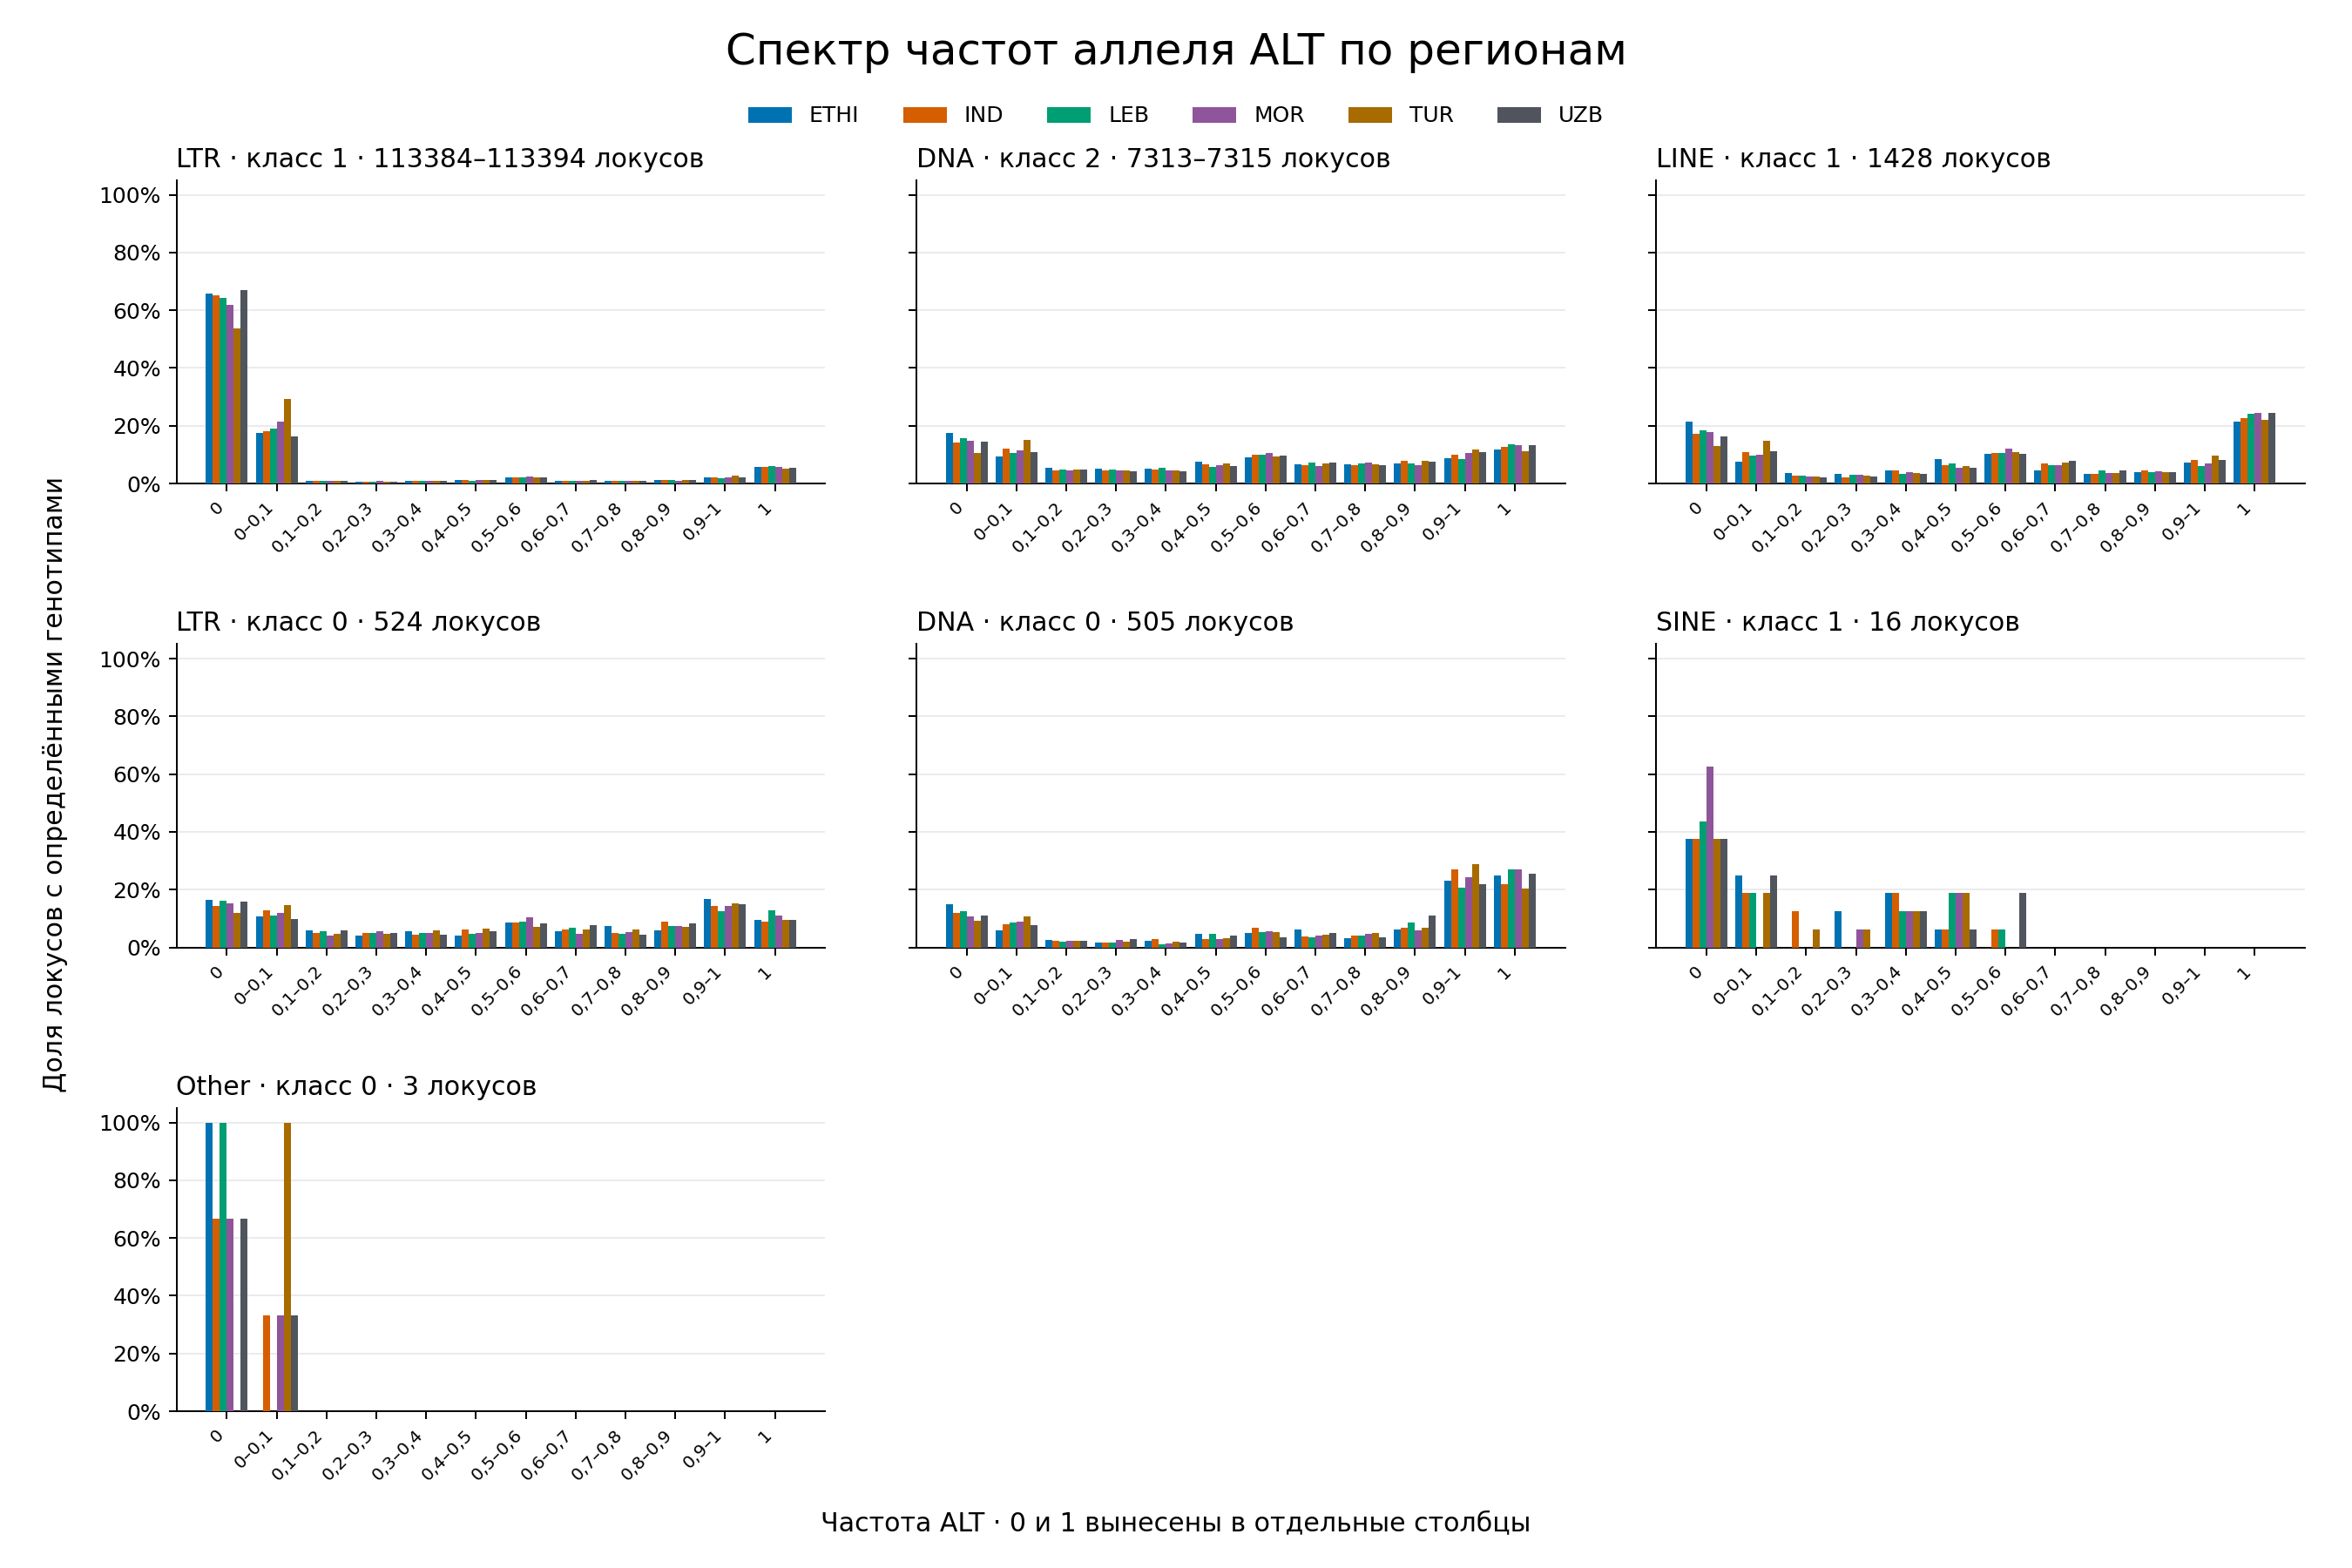

In [2]:
run_stage("stage1.py", "plot_stage1.py")
figure("stage1_spectrum.png")

## 2. Генетическая дифференциация

Основная панель содержит локусы с ≥95% определённых генотипов среди 141 образца. Проверка устойчивости использует локусы с полным покрытием. Одноуровневая AMOVA использует квадраты евклидовых расстояний между дозировками ALT. Для AMOVA пропуск заменялся средним по локусу среди всех образцов. Для FST Вейра–Кокерхэма использованы фактические числа генотипов и гетерозигот с агрегацией компонентов дисперсии по локусам. На тепловой карте показаны описательные попарные оценки.

У AMOVA односторонний тест по 9 999 перестановкам меток целых образцов сохраняет размеры групп. На основной панели межрегиональная доля составила 1,74%, а на полной — 2,75%. Для обеих панелей p = 0,0001. Наибольшая попарная оценка получена для ETHI–UZB, минимальная для MOR–TUR. Отрицательные оценки, близкие к нулю, сохранены в таблице.

region,samples,missing_rate_all_loci
ETHI,20,0.01249868084588221
IND,24,0.06450900407246553
LEB,19,0.01961875911925367
MOR,22,0.02804134210555447
TUR,35,0.03020172910662824
UZB,21,0.08814191585632913


panel,loci,phi_st,permutation_p,global_wc_fst
call95,92689,0.017396119504270287,0.0001,0.006175805929189499
complete,5118,0.027539042001189926,0.0001,0.007988203013949736


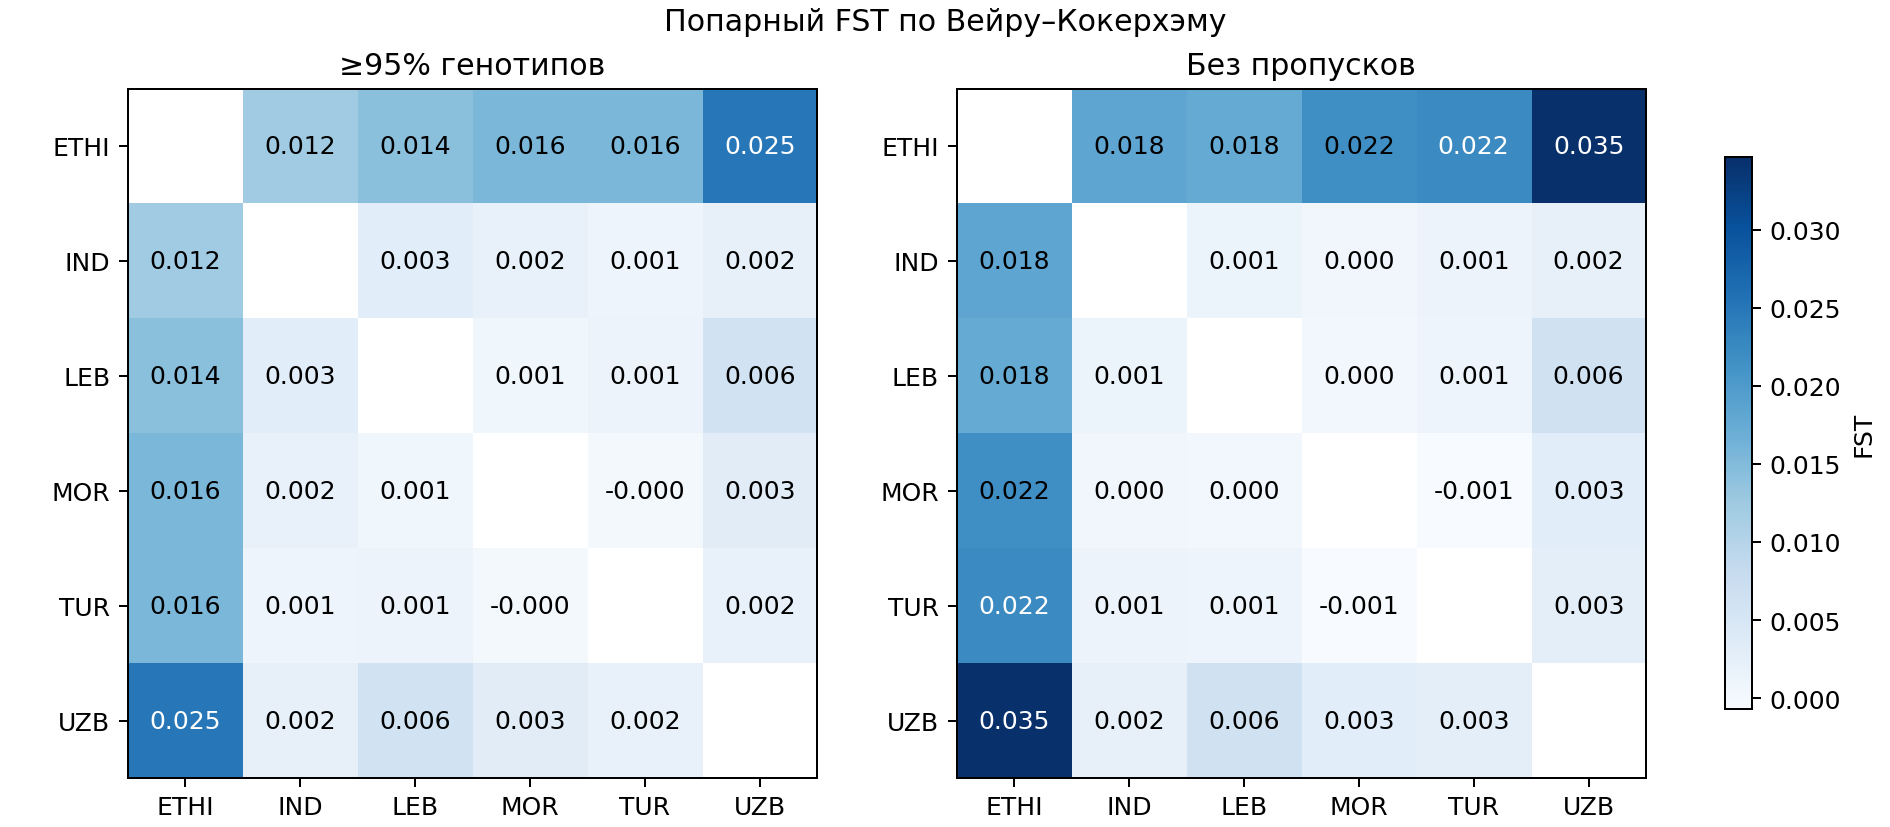

In [3]:
run_stage("stage2.py")
table("stage2_missingness.csv")
table("stage2_amova.csv", ["panel", "loci", "phi_st", "permutation_p", "global_wc_fst"])
figure("stage2_fst.png")

## 3. Эмпирические маркеры дрейфа

Для каждого локуса рассчитали дисперсию частоты ALT по шести регионам. Сопоставили порядки и классы TE внутри интервалов общей частоты. Приватный ALT определён как обнаруженный ровно в одном регионе. Редкий ALT имеет частоту >0 и ≤5% в объединённой полной выборке образцов соответствующей панели. Для крайних частот считали доли локусов с ALT = 0 или ALT = 1 среди определённых генотипов.

В 100 подвыборках брали по 19 образцов на регион без возвращения. Доля локусов с ALT, обнаруженным только в Турции, снизилась с 9,83% до 6,28% на основной панели. В среднем 10,99% локусов, классифицированных как редкие, остались без обнаруженного ALT во всех подвыборках регионов. Отсутствие аллеля в подвыборке отражает наблюдаемость. Динамику утраты по поколениям рассматриваем в симуляциях.

panel,loci,loci_all_regions,rare_loci,private_alt_fraction,mean_frequency_variance,balanced_loci_min,balanced_loci_max
call95,92689,92689,59496,0.363689326673068,0.0006233247033691534,92689,92689
complete,5118,5118,1031,0.12231340367330988,0.001394178949397211,5118,5118


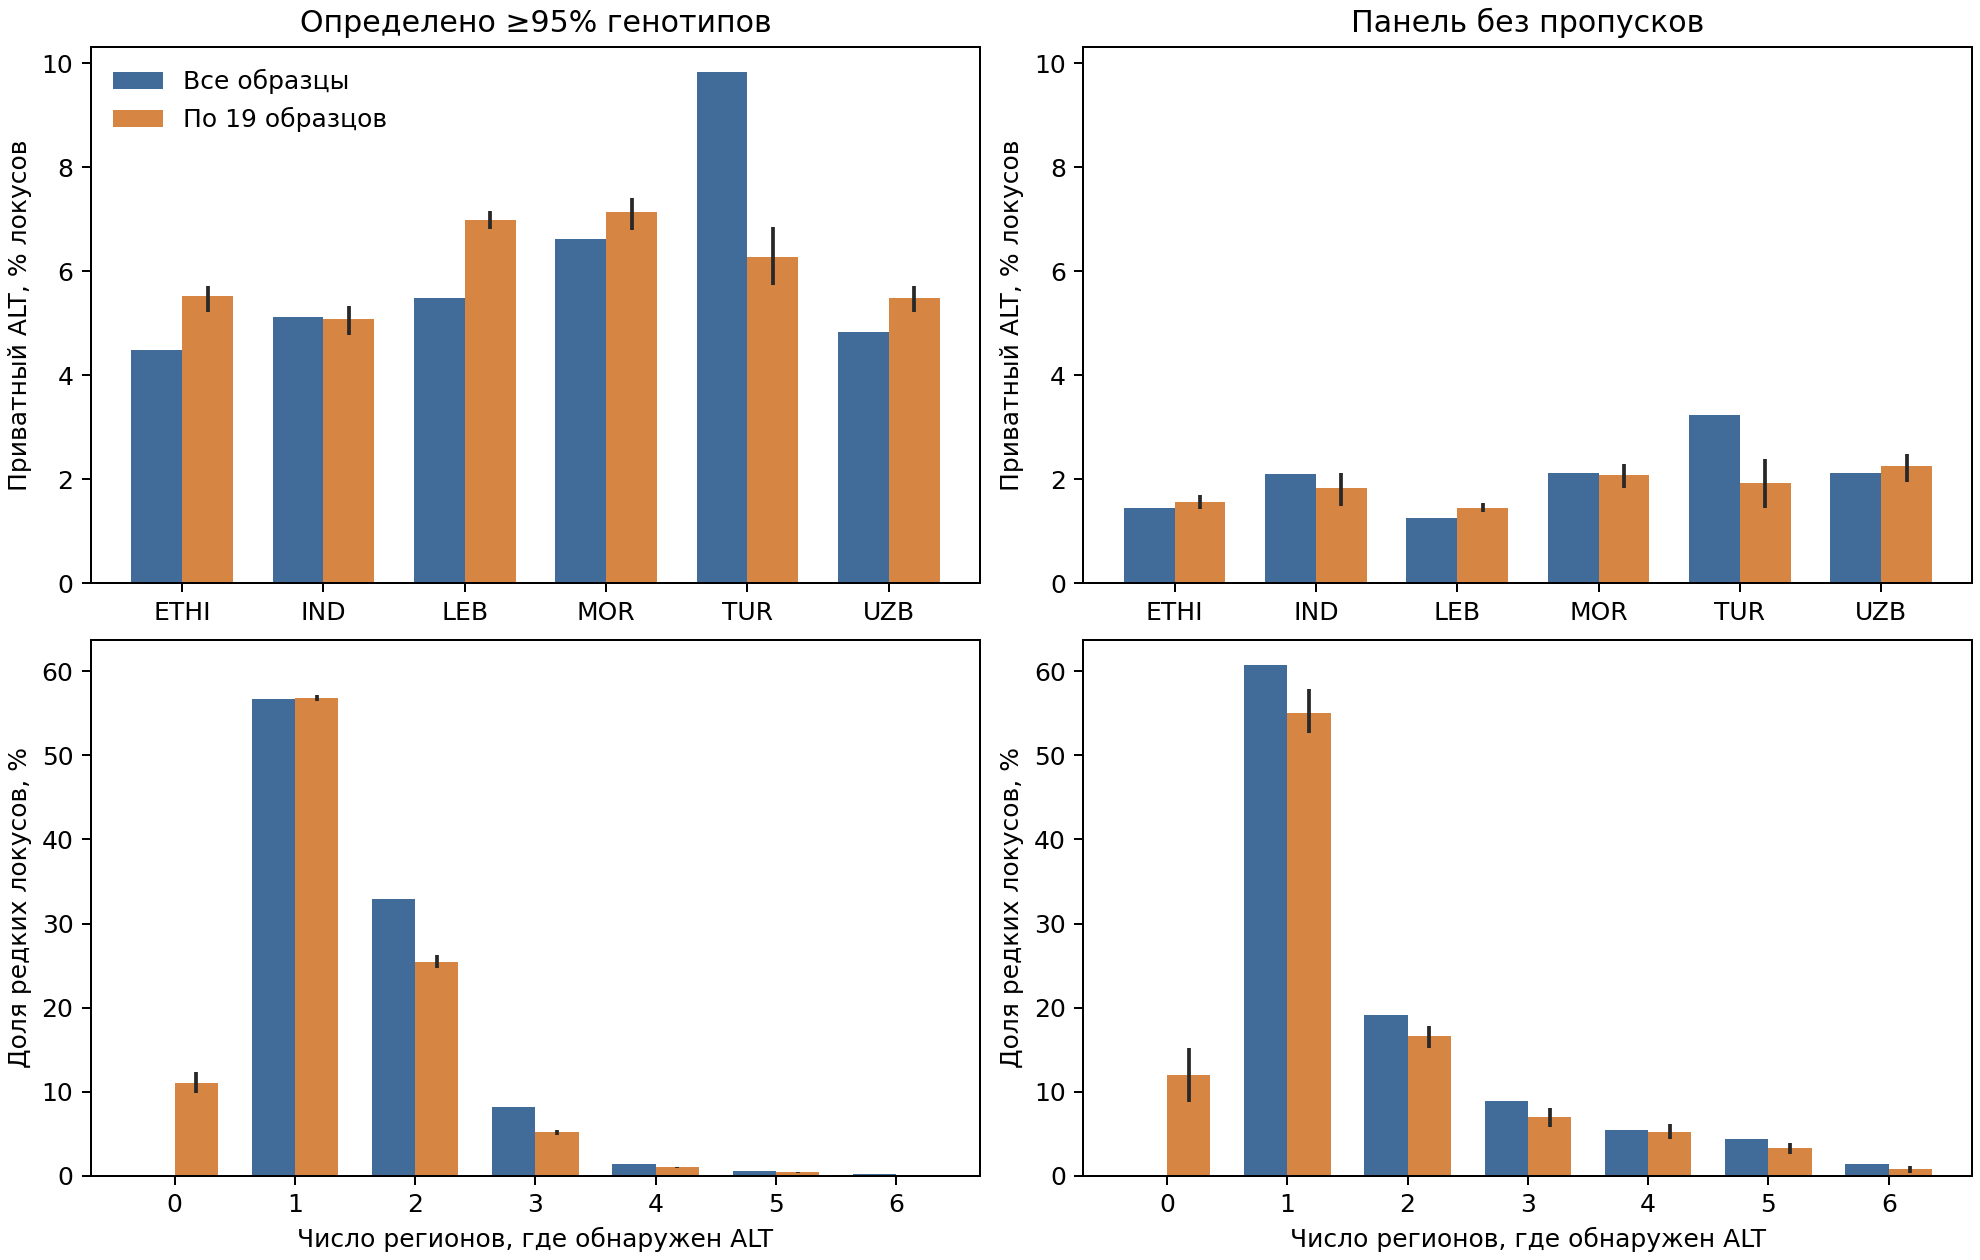

In [4]:
run_stage("stage3.py")
table("stage3_summary.csv")
figure("stage3_drift.png")

## 4. Прямое моделирование Райта–Фишера

Рассмотрены изоляция, симметричная островная миграция и одномерная ступенчатая миграция. В каждой модели все шесть популяций начинали с одинаковой частоты для данного локуса. Частоты предков взяты из Beta(0,1; 3) и Beta(0,3; 2) и округлены до числа копий от 1 до 2Ne−1. После смешивания соседних популяций счёт аллеля в каждом поколении моделировали биномиальной выборкой из 2Ne копий. Миграция ступенчатой модели симметрична, каждое ребро получает m/2, у крайних групп есть по одному ребру. Две цепочки выбраны по минимальной суммарной длине путей между географическими центрами регионов.

Сетка включает Ne ∈ {100, 500}, m ∈ {0,005, 0,03} для сценариев с миграцией, t ∈ {10, 50, 150}. Изоляция использует m = 0. В каждой настройке 20 повторов по 2 048 локусов. Выборки диплоидных генотипов из симуляций повторяют размеры групп и маски пропусков наблюдаемой панели. Сравнение ведётся для всей панели ≥95% и для её локусов, полиморфных в объединённой выборке. Инициализация генератора случайных чисел для воспроизводимых расчётов задана значением 2026.

Красная линия — эмпирическое значение, точки — медианы симуляций, отрезки — центральные 95% по каждой статистике. Для каждого сценария показана настройка с минимальной среднеквадратической относительной ошибкой по трём статистикам. Интервалы описывают разброс симуляций при заданном сценарии, оценка крайних квантилей основана на 20 повторах.

На полной основной панели островная модель с Ne = 500, m = 0,03 и t = 10 воспроизвела FST и дисперсию частот по этому критерию. Доля приватных ALT составила 36,37% в данных и 15,77% по медиане этой модели. Ни одна настройка не воспроизвела долю приватных ALT для всей панели, а на полиморфном подмножестве ни одна не воспроизвела дисперсию региональных частот. Ни одна проверенная комбинация не попала в эмпирические значения всех трёх показателей сразу. В ближайшем островном сценарии медианная глобальная утрата изначально редких аллелей достигла 26%, 62% и 79% через 10, 50 и 150 поколений.

ascertainment,fst,private_alt_fraction,frequency_variance
all,0.006175805929189499,0.363689326673068,0.0006233247033691534
polymorphic,0.006175805929189499,0.43331276672322483,0.0007426518513880336


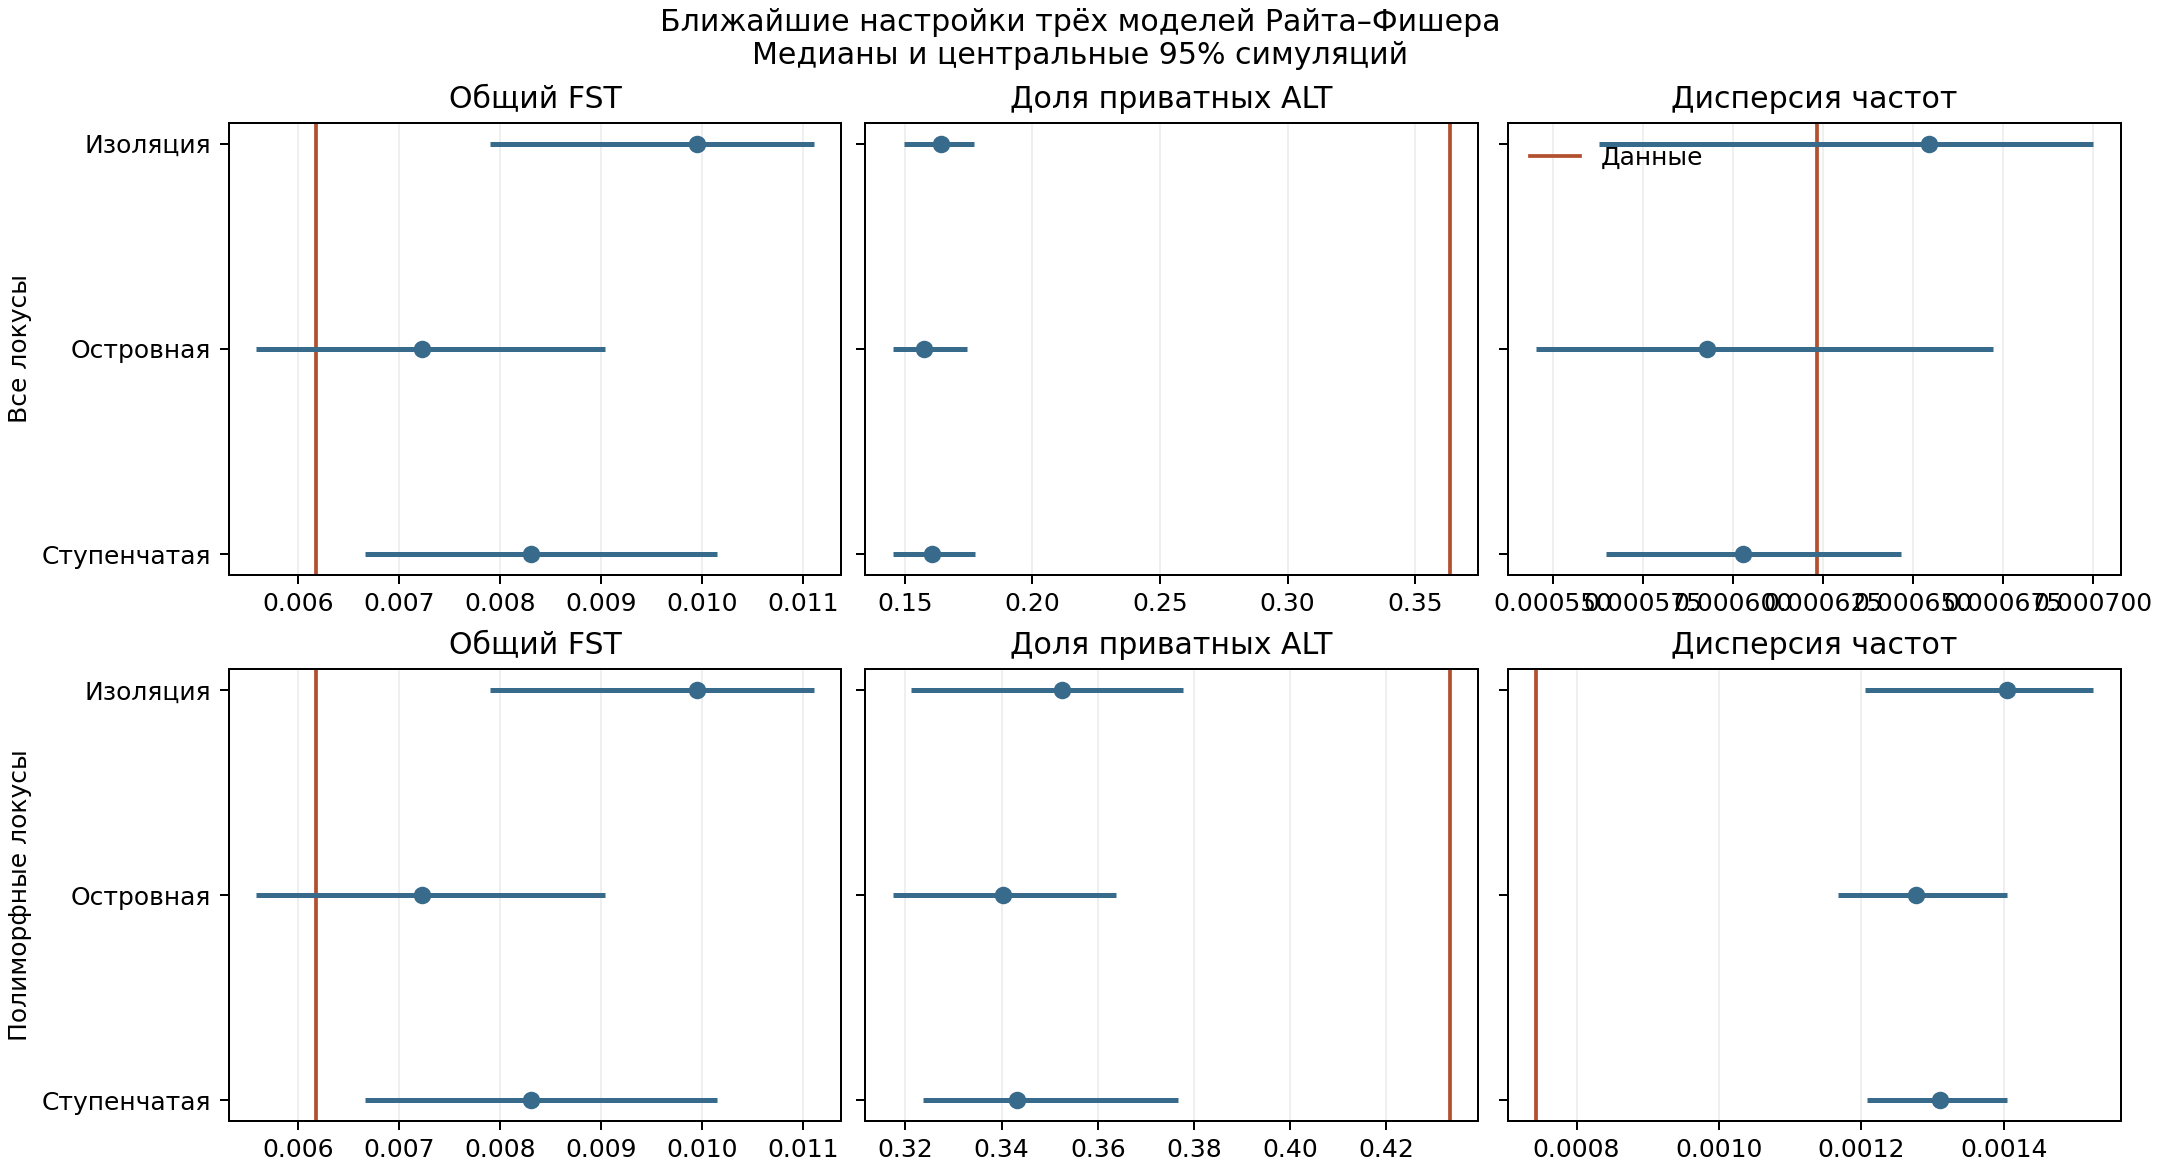

In [5]:
run_stage("stage4.py")
table("stage4_empirical.csv")
figure("stage4_models.png")

## 5. Устойчивость деревьев к метрике расстояния

Евклидово расстояние — корень из среднего квадрата разностей частот ALT. Хордовое расстояние — корень из среднего квадрата евклидова расстояния между векторами (√p, √(1−p)). Построены UPGMA и неукоренённые Neighbor-Joining (NJ). Поддержка основана на 1 000 повторных выборках локусов с возвращением. Для UPGMA проверялись клады, для NJ — неукоренённые разбиения. Бутстрап отдельных локусов не учитывает сцепление.

На основной панели евклидово UPGMA группирует Марокко и Турцию (99,9%), хордовое — Индию и Турцию (100%). Топология NJ совпала для двух метрик, хотя поддержка ветви ETHI–IND изменилась с 65,2% до 94,1%. В панели без пропусков обе метрики NJ сгруппировали ETHI и LEB. Ультраметричность UPGMA задаёт одинаковое расстояние от корня до всех листьев. Для интерпретации ветвей как времени расхождения это предполагает одинаковый темп накопления различий по линиям. У NJ ориентир корня при отрисовке условный.

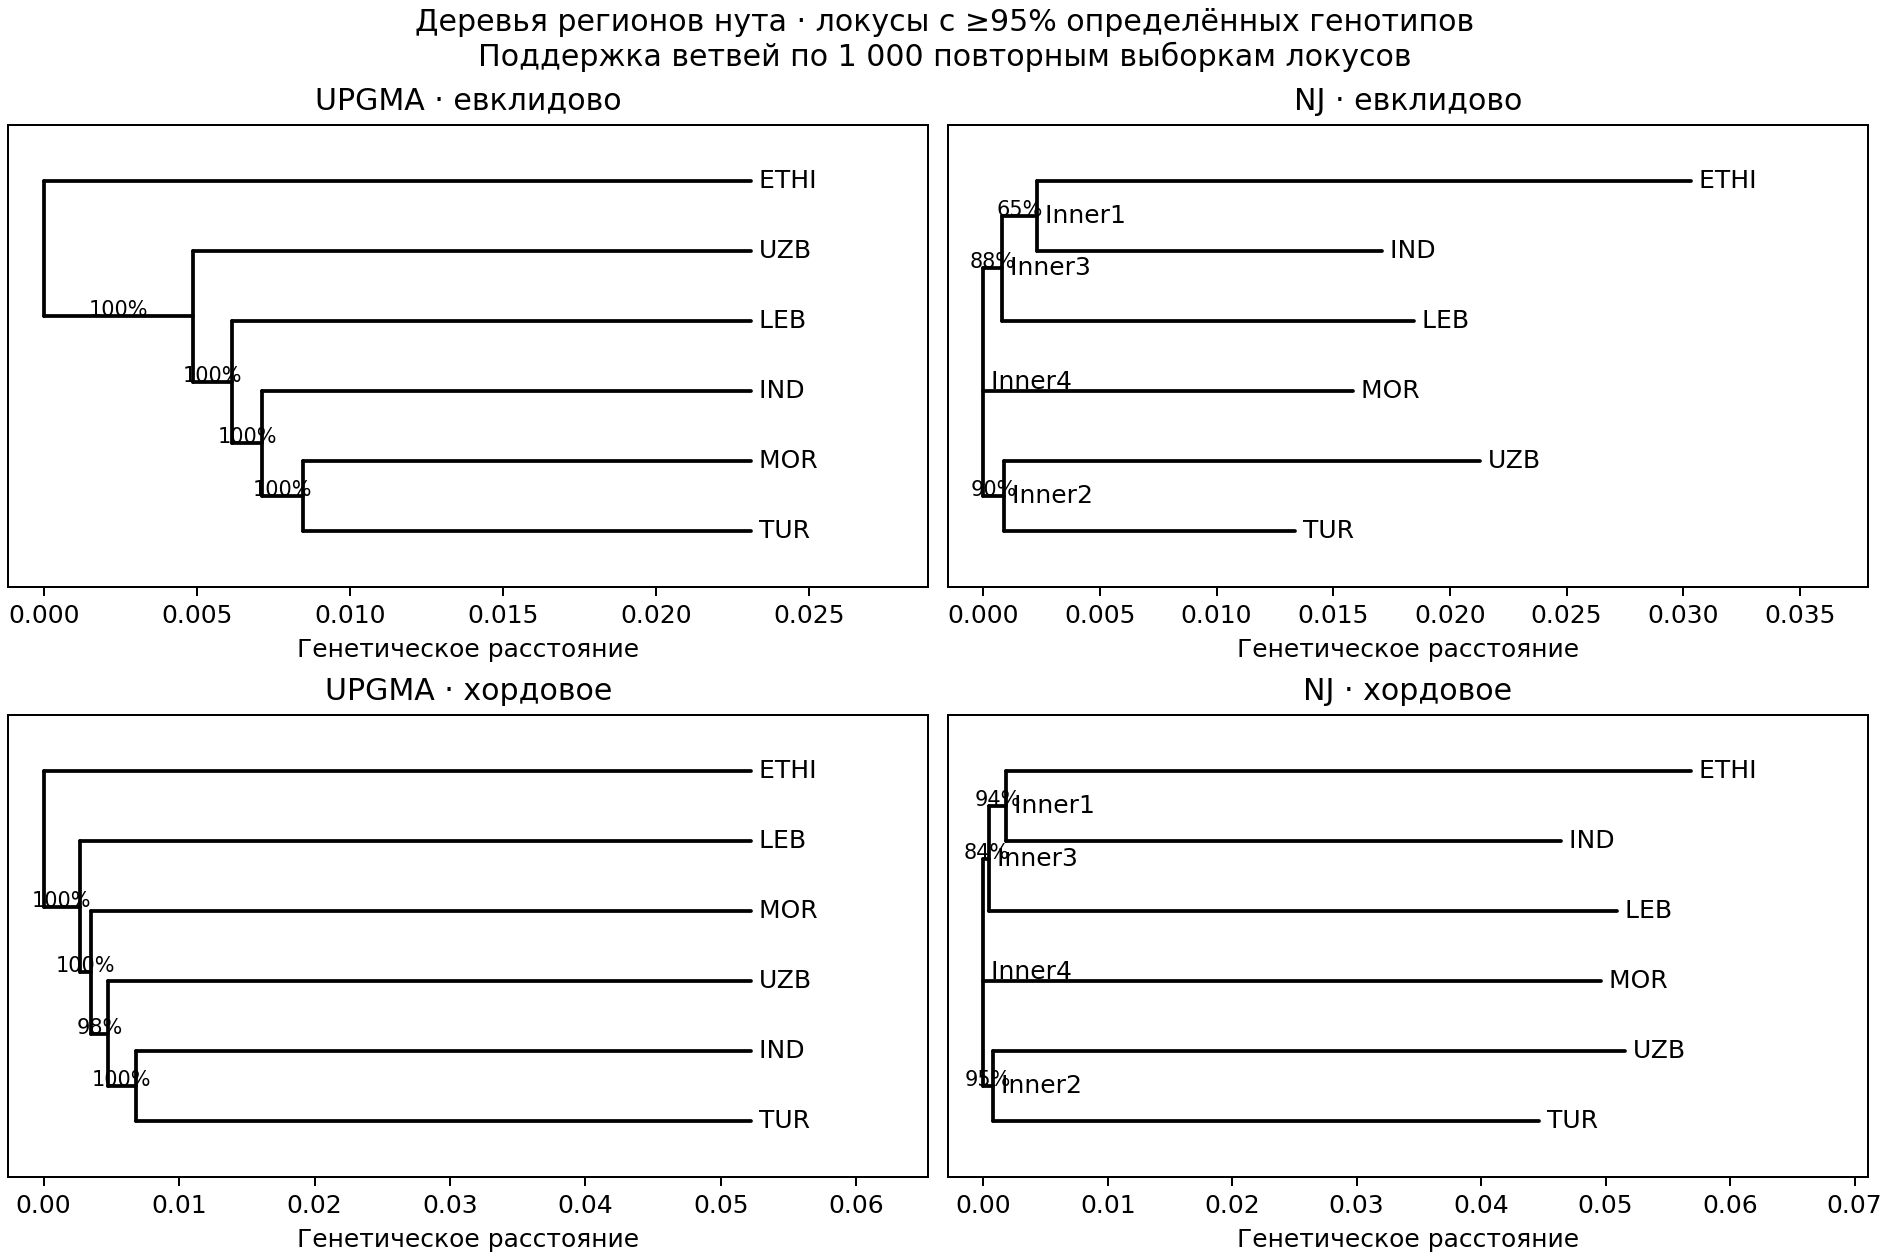

In [6]:
run_stage("stage5.py")
figure("stage5_trees.png")

## 6. Сопоставление генетики и географии

После сопоставления генотипов осталось 102 места для 141 образца. Генетические частоты рассчитаны по местам сбора, каждое место имеет одинаковый вес в ординации. Для отсутствующих на уровне места генотипов использовали общую частоту локуса. Два первых измерения PCoA рассчитаны на основе расстояний по дуге большого круга между координатами и отдельно для каждой генетической метрики. Совпадение конфигураций оценивается корреляцией Прокруста и 9 999 перестановками мест по всему набору и внутри регионов.

На основной панели r = 0,279–0,282 и p = 0,0007 при глобальном перемешивании. Перестановки внутри регионов дали p около 0,69; сходный результат получен на полной панели. Это совместимо с географически структурированными различиями между регионами. Внутри регионов дополнительного соответствия в двух генетических измерениях не обнаружено. Две генетические оси объяснили 7–11% генетической вариации, поэтому вывод описывает только эту ординацию. Координаты интерпретированы как места сбора по метаданным; точность полевого измерения отдельно не верифицировалась.

panel,metric,sites,procrustes_r,p_global,p_within_region
call95,euclidean,102,0.2794179885390224,0.0007,0.6922
call95,chord,102,0.28240484187323883,0.0007,0.6889
complete,euclidean,102,0.34500327068907083,0.0001,0.702
complete,chord,102,0.3434292706301965,0.0001,0.6901


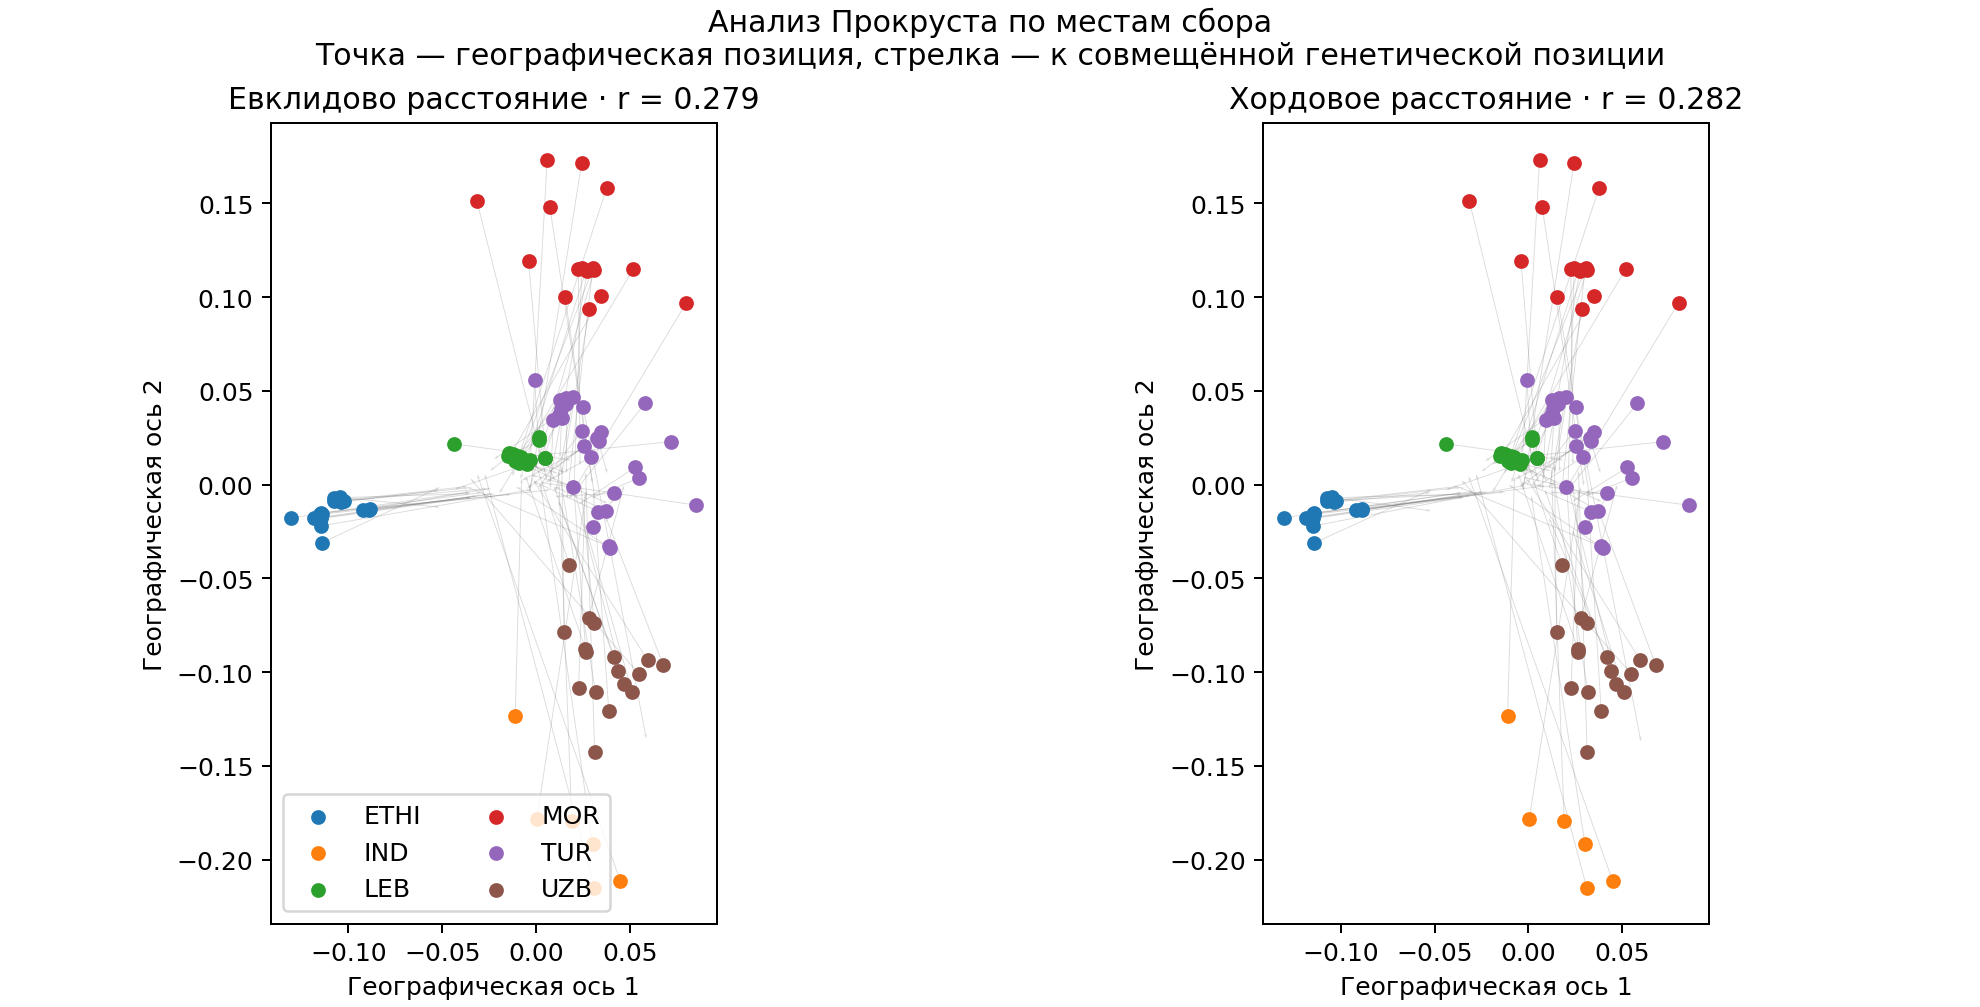

In [7]:
run_stage("stage6.py")
table("stage6_procrustes.csv", ["panel", "metric", "sites", "procrustes_r", "p_global", "p_within_region"])
figure("stage6_procrustes.png")

## Обсуждение

Региональная структура статистически различима, но доля вариации между регионами по AMOVA невелика. Совместимость с данными зависит и от статистики, и от фильтра: например, приватные ALT трудно воспроизвести на всей панели, тогда как в полиморфном подмножестве систематически не совпадает дисперсия частот. Следовательно, проверенные нейтральные сценарии недостаточны для одновременного описания всех трёх показателей на выбранной сетке.

Расхождения могут быть связаны с отбором, нестационарной динамикой вставок или миграцией вне простых симметричных схем. Есть и альтернативы в измерениях: виды локусов, попавшие в VCF, стратификация пропусков и ошибок генотипирования, неизвестная ориентация вставки относительно ALT и ограниченность начальных спектров в симуляции. Поэтому тип процесса по остаткам однозначно установить нельзя. Расхождения между UPGMA и NJ при смене метрики или панели дополнительно ограничивают реконструкцию демографической истории по этим деревьям.

### Литература

- [Excoffier, Smouse & Quattro (1992). Analysis of molecular variance inferred from metric distances among DNA haplotypes](https://doi.org/10.1093/genetics/131.2.479)
- [Weir & Cockerham (1984). Estimating F-statistics for the analysis of population structure](https://doi.org/10.1111/j.1558-5646.1984.tb05657.x)
- [Kimura & Weiss (1964). The stepping stone model of population structure](https://doi.org/10.1093/genetics/49.4.561)
- [Saitou & Nei (1987). The neighbor-joining method](https://doi.org/10.1093/oxfordjournals.molbev.a040454)
- [Peres-Neto & Jackson (2001). Procrustean superimposition](https://doi.org/10.1007/s004420100720)